In [1]:
import sys
import os
import time
from pathlib import Path

# Đảm bảo đường dẫn import được module từ BTL03_Keras_to_PyTorch
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

from src.datasets import make_hand_depth_loaders

# Thiết lập thiết bị chạy (ưu tiên CUDA nếu có GPU NVIDIA)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

# Nạp dữ liệu với batch_size = 8 theo chuẩn Keras gốc
data_dir = PROJECT_ROOT / "data" / "segnet"
loaders = make_hand_depth_loaders(str(data_dir), batch_size=8)
train_loader = loaders["train"]
test_loader = loaders["test"]

# Kiểm tra shape một batch mẫu
sample_imgs, sample_masks = next(iter(train_loader))
print(f"Input batch shape : {sample_imgs.shape}  (Kỳ vọng: [8, 1, 96, 96])")
print(f"Mask batch shape  : {sample_masks.shape}  (Kỳ vọng: [8, 96, 96])")

Device: cpu
Input batch shape : torch.Size([8, 1, 96, 96])  (Kỳ vọng: [8, 1, 96, 96])
Mask batch shape  : torch.Size([8, 96, 96])  (Kỳ vọng: [8, 96, 96])


In [2]:
class HandSegNet(nn.Module):
    def __init__(self, in_channels=1, num_classes=7):
        super(HandSegNet, self).__init__()
        
        # --- ENCODER ---
        # Khối 1: 96x96 -> 48x48
        self.enc1 = nn.Sequential(
            nn.Conv2d(in_channels, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # Khối 2: 48x48 -> 24x24
        self.enc2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # Khối 3: 24x24 -> 12x12
        self.enc3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # --- DECODER ---
        # Khối 3 Up: 12x12 -> 24x24
        self.dec3 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )
        
        # Khối 2 Up: 24x24 -> 48x48
        self.dec2 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        
        # Khối 1 Up: 48x48 -> 96x96
        self.dec1 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, num_classes, kernel_size=1)
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        
        d3 = self.dec3(e3)
        d2 = self.dec2(d3)
        out = self.dec1(d2)
        return out

model = HandSegNet(in_channels=1, num_classes=7).to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Tổng số tham số trainable: {total_params:,}")

Tổng số tham số trainable: 2,291,207


In [3]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)
epochs = 15

train_loss_history = []
train_acc_history = []

start_time = time.time()

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct_pixels = 0
    total_pixels = 0
    
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        
        preds = torch.argmax(outputs, dim=1)
        correct_pixels += (preds == masks).sum().item()
        total_pixels += masks.numel()
        
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = correct_pixels / total_pixels
    train_loss_history.append(epoch_loss)
    train_acc_history.append(epoch_acc)
    
    print(f"Epoch [{epoch+1:02d}/{epochs}] - Loss: {epoch_loss:.4f} - Pixel Acc: {epoch_acc*100:.2f}%")

total_training_time = time.time() - start_time
print(f"\nThời gian huấn luyện: {total_training_time:.2f}s")

Epoch [01/15] - Loss: 0.8513 - Pixel Acc: 76.03%
Epoch [02/15] - Loss: 0.5666 - Pixel Acc: 82.75%
Epoch [03/15] - Loss: 0.4553 - Pixel Acc: 85.57%
Epoch [04/15] - Loss: 0.3796 - Pixel Acc: 87.73%
Epoch [05/15] - Loss: 0.3236 - Pixel Acc: 89.40%
Epoch [06/15] - Loss: 0.2814 - Pixel Acc: 90.68%
Epoch [07/15] - Loss: 0.2514 - Pixel Acc: 91.56%
Epoch [08/15] - Loss: 0.2252 - Pixel Acc: 92.38%
Epoch [09/15] - Loss: 0.2000 - Pixel Acc: 93.16%
Epoch [10/15] - Loss: 0.1825 - Pixel Acc: 93.68%
Epoch [11/15] - Loss: 0.1760 - Pixel Acc: 93.84%
Epoch [12/15] - Loss: 0.1635 - Pixel Acc: 94.22%
Epoch [13/15] - Loss: 0.1493 - Pixel Acc: 94.66%
Epoch [14/15] - Loss: 0.1424 - Pixel Acc: 94.87%
Epoch [15/15] - Loss: 0.1363 - Pixel Acc: 95.05%

Thời gian huấn luyện: 2518.72s


In [4]:
def compute_miou(preds, targets, num_classes=7):
    ious = []
    for cls in range(num_classes):
        pred_inds = (preds == cls)
        target_inds = (targets == cls)
        intersection = (pred_inds & target_inds).sum().float()
        union = (pred_inds | target_inds).sum().float()
        if union > 0:
            ious.append((intersection / union).item())
    return float(np.mean(ious)) if ious else 0.0

model.eval()
test_loss = 0.0
correct_pixels = 0
total_pixels = 0
total_miou = 0.0

with torch.no_grad():
    for images, masks in test_loader:
        images, masks = images.to(device), masks.to(device)
        outputs = model(images)
        loss = criterion(outputs, masks)
        
        test_loss += loss.item() * images.size(0)
        preds = torch.argmax(outputs, dim=1)
        
        correct_pixels += (preds == masks).sum().item()
        total_pixels += masks.numel()
        total_miou += compute_miou(preds, masks)

final_test_loss = test_loss / len(test_loader.dataset)
final_test_acc = correct_pixels / total_pixels
final_test_miou = total_miou / len(test_loader)

print("=" * 45)
print(f"Test Loss            : {final_test_loss:.4f}")
print(f"Test Pixel Accuracy  : {final_test_acc*100:.2f}%")
print(f"Test Mean IoU (mIoU) : {final_test_miou:.4f}")
print("=" * 45)

Test Loss            : 0.5042
Test Pixel Accuracy  : 84.72%
Test Mean IoU (mIoU) : 0.5892


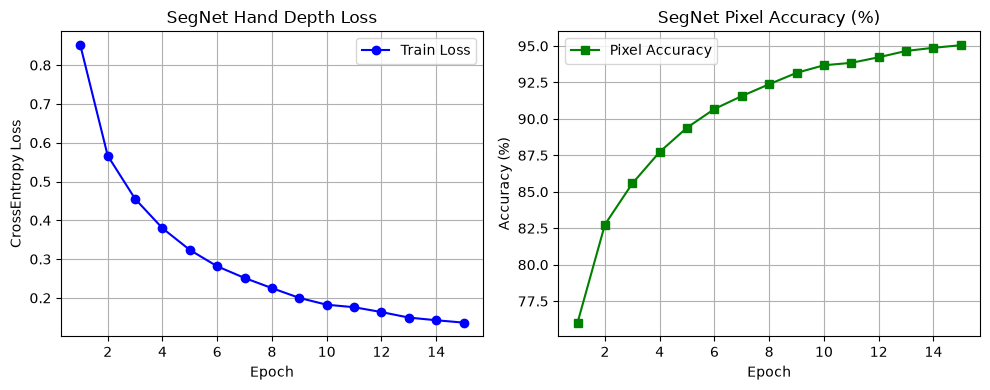

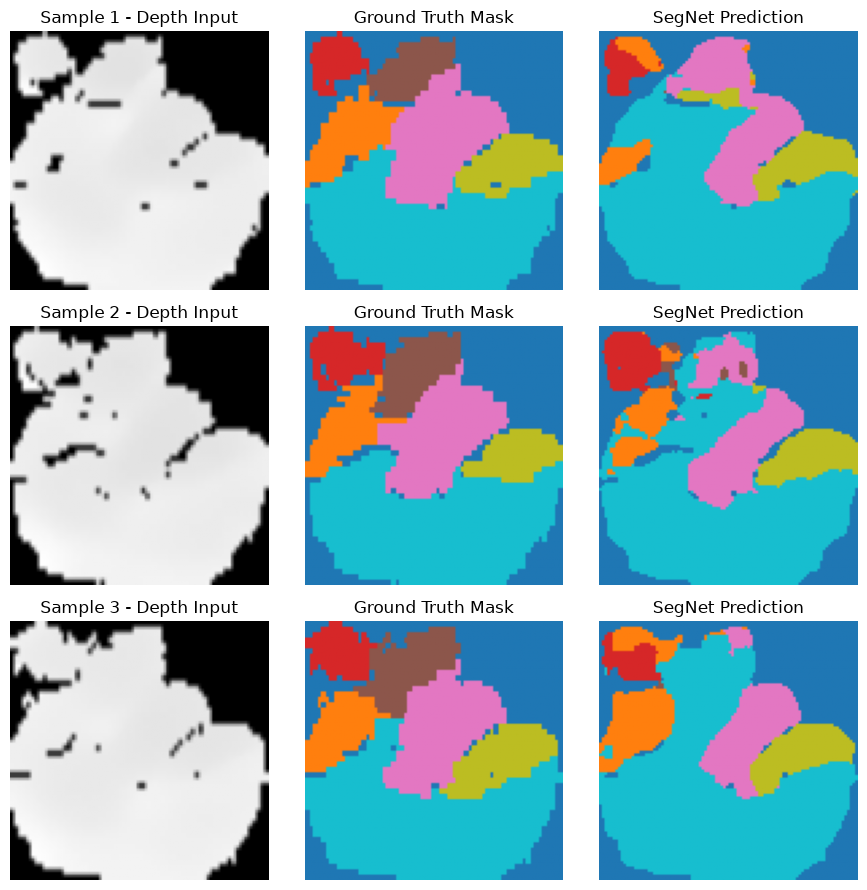

In [5]:
plots_dir = PROJECT_ROOT / "results" / "plots"
plots_dir.mkdir(parents=True, exist_ok=True)

# 1. Vẽ Learning Curve
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), train_loss_history, marker="o", color="blue", label="Train Loss")
plt.title("SegNet Hand Depth Loss")
plt.xlabel("Epoch")
plt.ylabel("CrossEntropy Loss")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), [acc * 100 for acc in train_acc_history], marker="s", color="green", label="Pixel Accuracy")
plt.title("SegNet Pixel Accuracy (%)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(plots_dir / "segnet_learning_curve.png", dpi=300)
plt.show()

# 2. Hiển thị 3 mẫu dự đoán so với Ground Truth
model.eval()
test_iter = iter(test_loader)
images, masks = next(test_iter)
with torch.no_grad():
    preds = torch.argmax(model(images.to(device)), dim=1).cpu()

fig, axs = plt.subplots(3, 3, figsize=(9, 9))
for i in range(3):
    axs[i, 0].imshow(images[i, 0].cpu(), cmap="gray")
    axs[i, 0].set_title(f"Sample {i+1} - Depth Input")
    axs[i, 1].imshow(masks[i].cpu(), cmap="tab10", vmin=0, vmax=6)
    axs[i, 1].set_title("Ground Truth Mask")
    axs[i, 2].imshow(preds[i], cmap="tab10", vmin=0, vmax=6)
    axs[i, 2].set_title("SegNet Prediction")
    for j in range(3):
        axs[i, j].axis("off")

plt.tight_layout()
plt.savefig(plots_dir / "segnet_prediction_samples.png", dpi=300)
plt.show()